# Phase 3 Research Questions — Housing Activity and Traffic Safety

**Contributor:** Mohamed Walid  
**Analysis grain:** ZIP code, aggregated from validated ZIP-year observations  
**Full calendar years:** 2022–2025

## Introduction and research objectives

This notebook studies two associations between NYC building-development filings and traffic-safety outcomes after the housing and collision datasets have been integrated at ZIP code × year grain by `phase2_data_integration_issa.ipynb`.

1. Is demolition activity in a ZIP code associated with more or fewer collisions per housing job?
2. Do ZIP codes adding many planned dwelling units in new buildings have a different pedestrian injury rate than ZIP codes adding few?

Only complete calendar years are used. The partial January–October 2026 period is excluded, as are rows marked by Issa's integrated `low_data_flag`. These analyses describe associations and do not establish causation.

**Datasets used (NYC Open Data):** [DOB NOW: Build Job Application Filings (w9ak-ipjd)](https://data.cityofnewyork.us/d/w9ak-ipjd) and [Motor Vehicle Collisions, Crashes (h9gi-nx95)](https://data.cityofnewyork.us/d/h9gi-nx95).

## Input validation

The notebook requires Issa's final integrated dataset at `data/zip_year.csv`. ZIP codes are loaded as strings so leading zeros are preserved. Required columns, one-row-per-ZIP-year grain, numeric metrics, Boolean low-data flags, nonnegative counts, and the expected 2022–2026 year range are validated before analysis. Invalid records are not silently dropped or repaired.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pandas.api.types import is_bool_dtype

INPUT = Path("data/zip_year.csv")
OUTPUT_DIR = Path("assets/rq")
Q1_CHART = OUTPUT_DIR / "walid_q1.png"
Q2_CHART = OUTPUT_DIR / "walid_q2.png"
Q1_FINDING = OUTPUT_DIR / "walid_q1.md"
Q2_FINDING = OUTPUT_DIR / "walid_q2.md"

if not INPUT.exists():
    raise FileNotFoundError(
        "Missing data/zip_year.csv. This final integrated dataset must be produced "
        "by Issa's phase2_data_integration_issa.ipynb after PR #12 is merged."
    )

df = pd.read_csv(
    INPUT,
    dtype={"zip_code": "string"},
    low_memory=False,
)

required_columns = {
    "zip_code",
    "year",
    "borough",
    "housing_job_count",
    "demolition_job_count",
    "proposed_dwelling_units_new_buildings",
    "collision_count",
    "pedestrians_injured",
    "low_data_flag",
}
missing_columns = required_columns - set(df.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"

assert df["zip_code"].notna().all(), "Missing ZIP codes found."
assert df["zip_code"].str.fullmatch(r"\d{5}").all(), (
    "ZIP codes must be five-digit strings."
)

year_numeric = pd.to_numeric(df["year"], errors="coerce")
assert year_numeric.notna().all(), "Missing or non-numeric years found."
assert year_numeric.mod(1).eq(0).all(), "Fractional years found."
df["year"] = year_numeric.astype("int64")
assert df["year"].between(2022, 2026).all(), "Years outside 2022–2026 found."

numeric_columns = [
    "housing_job_count",
    "demolition_job_count",
    "proposed_dwelling_units_new_buildings",
    "collision_count",
    "pedestrians_injured",
]
for column in numeric_columns:
    converted = pd.to_numeric(df[column], errors="coerce")
    assert converted.notna().all(), f"{column} contains missing or non-numeric values."
    assert converted.mod(1).eq(0).all(), f"{column} contains fractional counts."
    assert converted.ge(0).all(), f"{column} contains negative counts."
    df[column] = converted.astype("int64")

if not is_bool_dtype(df["low_data_flag"].dtype):
    normalized_flags = df["low_data_flag"].astype("string").str.strip().str.lower()
    unexpected_flags = sorted(
        normalized_flags.dropna().loc[~normalized_flags.isin(["true", "false"])].unique()
    )
    assert not unexpected_flags, f"Unexpected low_data_flag values: {unexpected_flags}"
    assert normalized_flags.notna().all(), "Missing low_data_flag values found."
    df["low_data_flag"] = normalized_flags.map(
        {"true": True, "false": False}
    ).astype("boolean")
else:
    df["low_data_flag"] = df["low_data_flag"].astype("boolean")

assert df["low_data_flag"].notna().all(), "Missing low_data_flag values found."
assert not df.duplicated(["zip_code", "year"]).any(), (
    "The integrated input contains duplicate ZIP-year keys."
)

input_summary = pd.Series(
    {
        "Input rows": len(df),
        "Input columns": len(df.columns),
        "Unique ZIP codes": df["zip_code"].nunique(),
        "Minimum year": df["year"].min(),
        "Maximum year": df["year"].max(),
        "Duplicate ZIP-year keys": int(df.duplicated(["zip_code", "year"]).sum()),
    },
    name="Validated value",
)
display(input_summary.to_frame())
print("Input validation: PASS")

,Validated value
Input rows,1123
Input columns,25
Unique ZIP codes,232
Minimum year,2022
Maximum year,2026
Duplicate ZIP-year keys,0


Input validation: PASS


## Year and low-data filtering

The analysis uses 2022–2025 only. All 2026 rows are excluded because that year covers January through October rather than a complete calendar year. Within 2022–2025, the integrated `low_data_flag` is used exactly as delivered; it is not recalculated or reinterpreted here.

In [2]:
total_input_rows = len(df)
rows_excluded_2026 = int(df["year"].eq(2026).sum())

full_year_rows = df.loc[df["year"].between(2022, 2025)].copy()
rows_excluded_low_data = int(full_year_rows["low_data_flag"].eq(True).sum())
analysis_df = full_year_rows.loc[
    full_year_rows["low_data_flag"].eq(False)
].copy()

remaining_zip_year_rows = len(analysis_df)
remaining_unique_zips = analysis_df["zip_code"].nunique()

assert remaining_zip_year_rows > 0, "No ZIP-year observations remain after filtering."
assert not analysis_df.duplicated(["zip_code", "year"]).any(), (
    "Filtered data contains duplicate ZIP-year keys."
)
assert analysis_df["year"].between(2022, 2025).all(), (
    "Filtered analysis includes a non-full year."
)
assert analysis_df["low_data_flag"].eq(False).all(), (
    "Filtered analysis still contains low-data rows."
)

filter_summary = pd.Series(
    {
        "Total input rows": total_input_rows,
        "Rows excluded because year is 2026": rows_excluded_2026,
        "Low-data rows excluded within 2022–2025": rows_excluded_low_data,
        "Remaining ZIP-year observations": remaining_zip_year_rows,
        "Remaining unique ZIP codes": remaining_unique_zips,
    },
    name="Count",
)
display(filter_summary.to_frame())

,Count
Total input rows,1123
Rows excluded because year is 2026,225
Low-data rows excluded within 2022–2025,39
Remaining ZIP-year observations,859
Remaining unique ZIP codes,220


## Research Question 1

### Is demolition activity in a ZIP code associated with more or fewer collisions per housing job?

This question matters to New Yorkers because demolition can coincide with construction vehicles, temporary street changes, altered pedestrian routes, and other activity that may affect local travel conditions.

### Methodology

ZIP-year observations are aggregated to ZIP level across 2022–2025. Eligible ZIP codes have at least five demolition jobs and more than zero housing jobs. The outcome is collisions per 100 housing jobs. ZIPs at or above the 75th percentile of demolition-job totals form the top-quartile group; all other eligible ZIPs form the comparison group. Ties at the cutoff remain in the top group and are reported.

The primary statistic is the difference between the top group's median rate and the rest group's median rate. Medians are appropriate because rate distributions can be skewed and influenced by high-activity ZIPs. A 2,000-resample ZIP-level bootstrap estimates uncertainty without imposing a normal-distribution assumption.

An ordinary least-squares regression or difference in means was considered, but rejected as the primary approach because it would be more sensitive to outliers and stronger distributional assumptions. The box plot is appropriate because it displays group medians, spread, and every eligible ZIP observation.

In [3]:
q1_zip = (
    analysis_df.groupby("zip_code", observed=True)
    .agg(
        demolition_job_count=("demolition_job_count", "sum"),
        housing_job_count=("housing_job_count", "sum"),
        collision_count=("collision_count", "sum"),
    )
    .reset_index()
)

q1_candidates = q1_zip.loc[q1_zip["demolition_job_count"].ge(5)].copy()
q1_zero_housing_excluded = int(q1_candidates["housing_job_count"].eq(0).sum())
q1 = q1_candidates.loc[q1_candidates["housing_job_count"].gt(0)].copy()

assert len(q1) >= 2, "Fewer than two ZIP codes are eligible for Research Question 1."
q1["collisions_per_100_housing_jobs"] = (
    q1["collision_count"] / q1["housing_job_count"]
) * 100
assert np.isfinite(q1["collisions_per_100_housing_jobs"]).all(), (
    "Non-finite collision rates found in Research Question 1."
)

demolition_threshold = float(q1["demolition_job_count"].quantile(0.75))
q1["demolition_group"] = np.where(
    q1["demolition_job_count"].ge(demolition_threshold),
    "Top demolition quartile",
    "Rest",
)
ties_at_cutoff = int(q1["demolition_job_count"].eq(demolition_threshold).sum())

top_rates = q1.loc[
    q1["demolition_group"].eq("Top demolition quartile"),
    "collisions_per_100_housing_jobs",
].to_numpy(dtype=float)
rest_rates = q1.loc[
    q1["demolition_group"].eq("Rest"),
    "collisions_per_100_housing_jobs",
].to_numpy(dtype=float)
assert len(top_rates) > 0 and len(rest_rates) > 0, (
    "Research Question 1 produced an empty comparison group."
)

top_median = float(np.median(top_rates))
rest_median = float(np.median(rest_rates))
median_difference = top_median - rest_median

bootstrap_resamples = 2_000
bootstrap_rng = np.random.default_rng(42)
bootstrap_differences = np.empty(bootstrap_resamples, dtype=float)
for index in range(bootstrap_resamples):
    sampled_top = bootstrap_rng.choice(top_rates, size=len(top_rates), replace=True)
    sampled_rest = bootstrap_rng.choice(rest_rates, size=len(rest_rates), replace=True)
    bootstrap_differences[index] = np.median(sampled_top) - np.median(sampled_rest)

bootstrap_ci_low, bootstrap_ci_high = np.percentile(
    bootstrap_differences, [2.5, 97.5]
)

q1_results = pd.Series(
    {
        "Eligible ZIP codes": len(q1),
        "ZIPs excluded for zero housing jobs": q1_zero_housing_excluded,
        "75th-percentile demolition threshold": demolition_threshold,
        "Ties exactly at cutoff": ties_at_cutoff,
        "Top-quartile ZIPs": len(top_rates),
        "Rest-group ZIPs": len(rest_rates),
        "Top-group median collisions per 100 housing jobs": top_median,
        "Rest-group median collisions per 100 housing jobs": rest_median,
        "Difference in medians (top - rest)": median_difference,
        "Bootstrap 95% CI lower": bootstrap_ci_low,
        "Bootstrap 95% CI upper": bootstrap_ci_high,
        "Bootstrap resamples": bootstrap_resamples,
    },
    name="Result",
)
display(q1_results.to_frame())

,Result
Eligible ZIP codes,150.000000
ZIPs excluded for zero housing jobs,0.000000
75th-percentile demolition threshold,35.000000
Ties exactly at cutoff,4.000000
Top-quartile ZIPs,41.000000
Rest-group ZIPs,109.000000
Top-group median collisions per 100 housing jobs,118.216756
Rest-group median collisions per 100 housing jobs,101.206273
Difference in medians (top - rest),17.010484
Bootstrap 95% CI lower,-3.274388


### Research Question 1 visualization and finding

The chart compares the full distribution of collisions per 100 housing jobs between the two demolition groups. Individual points ensure that the group summaries do not hide ZIP-level variation. The executed code writes the chart and a one-paragraph, data-supported finding only after the real integrated dataset is available.

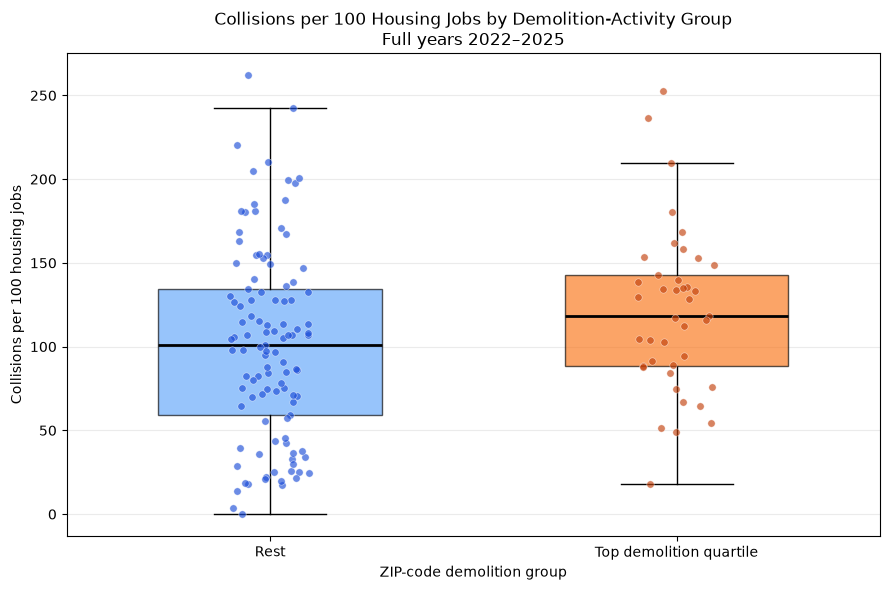

Across 150 eligible NYC ZIP codes in 2022–2025, the top demolition quartile began at 35.00 demolition jobs and contained 41 ZIPs, compared with 109 in the rest group. The median collision rate was 118.22 versus 101.21 collisions per 100 housing jobs, so the top group was higher by 17.01. The ZIP-level bootstrap 95% confidence interval for the signed difference was [-3.27, 42.42] and included zero; this is an association, not evidence that demolition activity caused collision outcomes.

In [4]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 6))
box = ax.boxplot(
    [rest_rates, top_rates],
    positions=[1, 2],
    widths=0.55,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 2},
)
for patch, color in zip(box["boxes"], ["#60A5FA", "#F97316"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

jitter_rng = np.random.default_rng(42)
for position, values, color in [
    (1, rest_rates, "#1D4ED8"),
    (2, top_rates, "#C2410C"),
]:
    jitter = jitter_rng.uniform(-0.10, 0.10, size=len(values))
    ax.scatter(
        np.full(len(values), position) + jitter,
        values,
        color=color,
        alpha=0.65,
        s=28,
        edgecolor="white",
        linewidth=0.4,
        zorder=3,
    )

ax.set_xticks([1, 2], ["Rest", "Top demolition quartile"])
ax.set_title("Collisions per 100 Housing Jobs by Demolition-Activity Group\nFull years 2022–2025")
ax.set_xlabel("ZIP-code demolition group")
ax.set_ylabel("Collisions per 100 housing jobs")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(Q1_CHART, dpi=180, bbox_inches="tight")
plt.show()

direction_q1 = "higher" if median_difference > 0 else "lower" if median_difference < 0 else "the same"
ci_statement_q1 = (
    "excluded zero"
    if bootstrap_ci_low > 0 or bootstrap_ci_high < 0
    else "included zero"
)
q1_finding_text = (
    f"Across {len(q1):,} eligible NYC ZIP codes in 2022–2025, the top demolition "
    f"quartile began at {demolition_threshold:,.2f} demolition jobs and contained "
    f"{len(top_rates):,} ZIPs, compared with {len(rest_rates):,} in the rest group. "
    f"The median collision rate was {top_median:,.2f} versus {rest_median:,.2f} "
    f"collisions per 100 housing jobs, so the top group was {direction_q1} by "
    f"{abs(median_difference):,.2f}. The ZIP-level bootstrap 95% confidence "
    f"interval for the signed difference was [{bootstrap_ci_low:,.2f}, "
    f"{bootstrap_ci_high:,.2f}] and {ci_statement_q1}; this is an association, "
    "not evidence that demolition activity caused collision outcomes."
)
Q1_FINDING.write_text(q1_finding_text + "\n", encoding="utf-8")
display(Markdown(q1_finding_text))

## Research Question 2

### Do ZIP codes adding many planned dwelling units in new buildings have a different pedestrian injury rate than ZIP codes adding few?

This question matters because planned residential growth can change travel demand, walking activity, construction exposure, and pressure on street infrastructure. It can help identify places where growth and pedestrian safety should be considered together.

### Methodology

ZIP-year observations are aggregated to ZIP level across 2022–2025. Planned dwelling units, pedestrian injuries, and collisions are summed. ZIPs with zero collisions are excluded only because their injury-rate denominator is undefined; ZIPs with zero planned dwelling units remain included.

Borough is assigned using the most frequent normalized non-missing borough label for each ZIP, with alphabetical tie-breaking. Inconsistencies and ties are reported. The outcome is pedestrians injured per 100 collisions.

Spearman rank correlation is calculated as the Pearson correlation between average-ranked planned dwelling units and injury rates. This is suitable for skewed activity measures and monotonic relationships. A Pearson correlation on raw values was considered but rejected because it would emphasize extreme values and assume a linear relationship. A two-sided 10,000-permutation test evaluates the rank association without relying on a parametric significance formula.

The bubble scatter plot preserves individual ZIPs while showing planned units, pedestrian injury rate, collision volume, and borough. The horizontal coordinate uses `log1p(planned units)` so zero-unit ZIPs remain visible at zero rather than being discarded.

In [5]:
borough_work = analysis_df[["zip_code", "borough"]].copy()
borough_work["borough"] = (
    borough_work["borough"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace("", pd.NA)
)

borough_variants = (
    borough_work.dropna(subset=["borough"])
    .groupby("zip_code", observed=True)["borough"]
    .nunique()
)
borough_inconsistent_zips = int(borough_variants.gt(1).sum())

borough_frequency = (
    borough_work.dropna(subset=["borough"])
    .groupby(["zip_code", "borough"], observed=True)
    .size()
    .rename("frequency")
    .reset_index()
)
borough_frequency["maximum_frequency"] = borough_frequency.groupby(
    "zip_code", observed=True
)["frequency"].transform("max")
borough_tied_zips = int(
    borough_frequency.loc[
        borough_frequency["frequency"].eq(borough_frequency["maximum_frequency"])
    ]
    .groupby("zip_code", observed=True)
    .size()
    .gt(1)
    .sum()
)
zip_borough = (
    borough_frequency.sort_values(
        ["zip_code", "frequency", "borough"],
        ascending=[True, False, True],
        kind="stable",
    )
    .drop_duplicates("zip_code", keep="first")
    .set_index("zip_code")["borough"]
)

q2_zip = (
    analysis_df.groupby("zip_code", observed=True)
    .agg(
        proposed_dwelling_units_new_buildings=(
            "proposed_dwelling_units_new_buildings",
            "sum",
        ),
        pedestrians_injured=("pedestrians_injured", "sum"),
        collision_count=("collision_count", "sum"),
    )
    .reset_index()
)
q2_zip["borough"] = q2_zip["zip_code"].map(zip_borough).astype("string")
missing_borough_zips = q2_zip.loc[q2_zip["borough"].isna(), "zip_code"].tolist()
assert not missing_borough_zips, (
    f"No valid borough assignment is available for ZIP codes: {missing_borough_zips}"
)

q2_zero_collision_excluded = int(q2_zip["collision_count"].eq(0).sum())
q2 = q2_zip.loc[q2_zip["collision_count"].gt(0)].copy()
assert len(q2) >= 3, "Fewer than three ZIP codes are eligible for Research Question 2."

q2["pedestrian_injuries_per_100_collisions"] = (
    q2["pedestrians_injured"] / q2["collision_count"]
) * 100
assert np.isfinite(q2["pedestrian_injuries_per_100_collisions"]).all(), (
    "Non-finite pedestrian injury rates found."
)

x_ranks = q2["proposed_dwelling_units_new_buildings"].rank(method="average")
y_ranks = q2["pedestrian_injuries_per_100_collisions"].rank(method="average")
assert x_ranks.nunique() > 1 and y_ranks.nunique() > 1, (
    "Spearman correlation is undefined because a ranked variable is constant."
)
spearman_rho = float(x_ranks.corr(y_ranks, method="pearson"))

x_centered = x_ranks.to_numpy(dtype=float) - x_ranks.mean()
y_centered = y_ranks.to_numpy(dtype=float) - y_ranks.mean()
correlation_denominator = np.sqrt(
    np.dot(x_centered, x_centered) * np.dot(y_centered, y_centered)
)
assert correlation_denominator > 0, "Permutation correlation denominator is zero."

permutations = 10_000
permutation_rng = np.random.default_rng(42)
permuted_rhos = np.empty(permutations, dtype=float)
for index in range(permutations):
    permuted_y = permutation_rng.permutation(y_centered)
    permuted_rhos[index] = np.dot(x_centered, permuted_y) / correlation_denominator

permutation_p_value = (
    1 + np.count_nonzero(np.abs(permuted_rhos) >= abs(spearman_rho))
) / (permutations + 1)

zero_dwelling_zips = int(
    q2["proposed_dwelling_units_new_buildings"].eq(0).sum()
)
q2_results = pd.Series(
    {
        "Eligible ZIP codes": len(q2),
        "ZIPs excluded for zero collisions": q2_zero_collision_excluded,
        "Minimum planned dwelling units": q2[
            "proposed_dwelling_units_new_buildings"
        ].min(),
        "Maximum planned dwelling units": q2[
            "proposed_dwelling_units_new_buildings"
        ].max(),
        "ZIPs with zero planned dwelling units": zero_dwelling_zips,
        "ZIPs with inconsistent borough labels": borough_inconsistent_zips,
        "ZIPs with a borough-frequency tie": borough_tied_zips,
        "Spearman rho": spearman_rho,
        "Two-sided permutation p-value": permutation_p_value,
        "Permutations": permutations,
    },
    name="Result",
)
display(q2_results.to_frame())

,Result
Eligible ZIP codes,214.000000
ZIPs excluded for zero collisions,6.000000
Minimum planned dwelling units,0.000000
Maximum planned dwelling units,4649.000000
ZIPs with zero planned dwelling units,47.000000
ZIPs with inconsistent borough labels,0.000000
ZIPs with a borough-frequency tie,0.000000
Spearman rho,0.236675
Two-sided permutation p-value,0.000500
Permutations,10000.000000


### Research Question 2 visualization and finding

The chart shows every eligible ZIP. Bubble area represents collision volume and color represents the ZIP-level majority borough. The transformed X coordinate is explicitly labeled; `log1p(0) = 0`, so ZIP codes with zero planned units remain visible. The executed code writes the chart and one-paragraph finding only from real results.

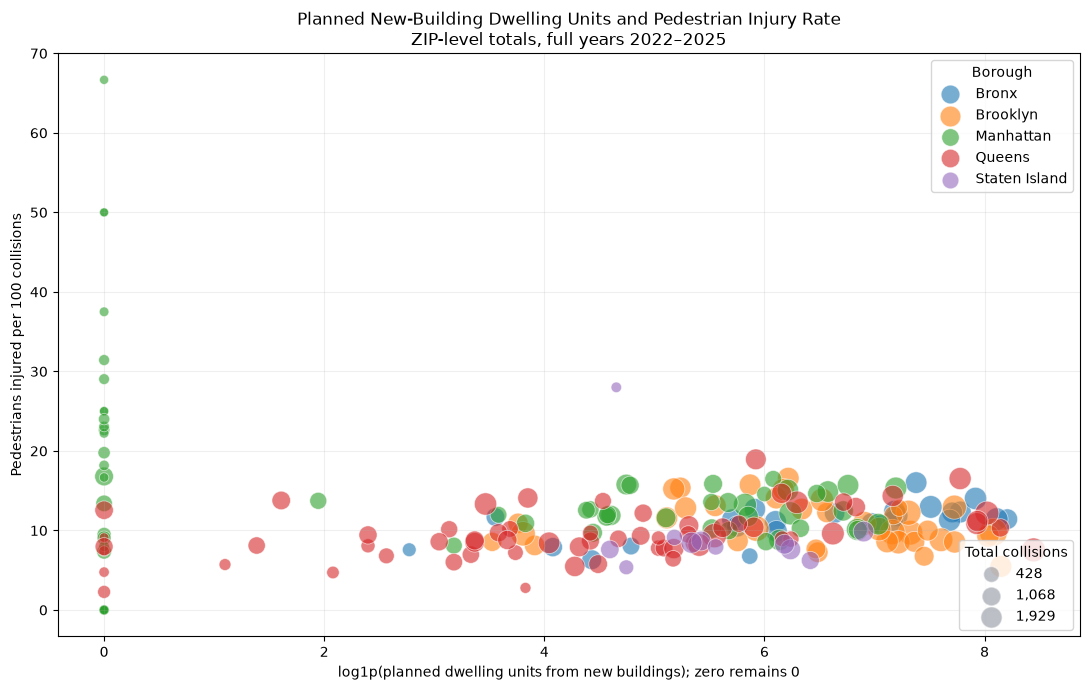

Among 214 eligible NYC ZIP codes in 2022–2025, planned dwelling-unit totals ranged from 0 to 4,649, including 47 ZIPs with zero planned units. The Spearman rank correlation between planned units and pedestrians injured per 100 collisions was 0.237, indicating a positive rank association; the two-sided 10,000-permutation p-value was 0.0005, so it was statistically detectable at the 0.05 level. The result is descriptive and does not show that planned housing activity caused pedestrian injuries.

In [6]:
q2["log1p_planned_dwelling_units"] = np.log1p(
    q2["proposed_dwelling_units_new_buildings"]
)
maximum_collisions = q2["collision_count"].max()
q2["bubble_size"] = 35 + 365 * np.sqrt(
    q2["collision_count"] / maximum_collisions
)

boroughs = sorted(q2["borough"].unique())
colors = plt.get_cmap("tab10").colors
borough_colors = {borough: colors[index % len(colors)] for index, borough in enumerate(boroughs)}

fig, ax = plt.subplots(figsize=(11, 7))
for borough in boroughs:
    borough_data = q2.loc[q2["borough"].eq(borough)]
    ax.scatter(
        borough_data["log1p_planned_dwelling_units"],
        borough_data["pedestrian_injuries_per_100_collisions"],
        s=borough_data["bubble_size"],
        color=borough_colors[borough],
        label=borough,
        alpha=0.60,
        edgecolor="white",
        linewidth=0.6,
    )

borough_legend = ax.legend(
    title="Borough",
    loc="upper right",
    frameon=True,
)
ax.add_artist(borough_legend)

size_values = np.unique(
    np.quantile(q2["collision_count"], [0.25, 0.50, 0.75]).astype(int)
)
size_handles = [
    ax.scatter(
        [],
        [],
        s=35 + 365 * np.sqrt(value / maximum_collisions),
        color="#6B7280",
        alpha=0.45,
        edgecolor="white",
        label=f"{value:,}",
    )
    for value in size_values
]
ax.legend(
    handles=size_handles,
    title="Total collisions",
    loc="lower right",
    frameon=True,
)

ax.set_title(
    "Planned New-Building Dwelling Units and Pedestrian Injury Rate\n"
    "ZIP-level totals, full years 2022–2025"
)
ax.set_xlabel("log1p(planned dwelling units from new buildings); zero remains 0")
ax.set_ylabel("Pedestrians injured per 100 collisions")
ax.grid(alpha=0.20)
plt.tight_layout()
fig.savefig(Q2_CHART, dpi=180, bbox_inches="tight")
plt.show()

direction_q2 = "positive" if spearman_rho > 0 else "negative" if spearman_rho < 0 else "no"
significance_q2 = (
    "statistically detectable at the 0.05 level"
    if permutation_p_value < 0.05
    else "not statistically distinguishable from zero at the 0.05 level"
)
q2_finding_text = (
    f"Among {len(q2):,} eligible NYC ZIP codes in 2022–2025, planned dwelling-unit "
    f"totals ranged from {q2['proposed_dwelling_units_new_buildings'].min():,} to "
    f"{q2['proposed_dwelling_units_new_buildings'].max():,}, including "
    f"{zero_dwelling_zips:,} ZIPs with zero planned units. The Spearman rank "
    f"correlation between planned units and pedestrians injured per 100 collisions "
    f"was {spearman_rho:.3f}, indicating a {direction_q2} rank association; the "
    f"two-sided 10,000-permutation p-value was {permutation_p_value:.4f}, so it was "
    f"{significance_q2}. The result is descriptive and does not show that planned "
    "housing activity caused pedestrian injuries."
)
Q2_FINDING.write_text(q2_finding_text + "\n", encoding="utf-8")
display(Markdown(q2_finding_text))

## Final output validation

The following checks confirm that both real-data charts and both finding paragraphs were created, are non-empty, and can be reopened. Successful completion is required before the analysis is reported as complete.

In [7]:
expected_outputs = [Q1_CHART, Q2_CHART, Q1_FINDING, Q2_FINDING]
missing_outputs = [path.as_posix() for path in expected_outputs if not path.exists()]
assert not missing_outputs, f"Missing research outputs: {missing_outputs}"
assert all(path.stat().st_size > 0 for path in expected_outputs), (
    "One or more research outputs are empty."
)

q1_image = plt.imread(Q1_CHART)
q2_image = plt.imread(Q2_CHART)
assert q1_image.size > 0 and q2_image.size > 0, "A chart could not be reopened."

q1_saved_finding = Q1_FINDING.read_text(encoding="utf-8").strip()
q2_saved_finding = Q2_FINDING.read_text(encoding="utf-8").strip()
assert q1_saved_finding == q1_finding_text, "Q1 finding file differs from notebook result."
assert q2_saved_finding == q2_finding_text, "Q2 finding file differs from notebook result."

output_validation = pd.DataFrame(
    {
        "output": [path.as_posix() for path in expected_outputs],
        "bytes": [path.stat().st_size for path in expected_outputs],
        "validated": True,
    }
)
display(output_validation)
print("All Phase 3 output validations: PASS")

,output,bytes,validated
0,assets/rq/walid_q1.png,87759,True
1,assets/rq/walid_q2.png,238237,True
2,assets/rq/walid_q1.md,493,True
3,assets/rq/walid_q2.md,501,True


All Phase 3 output validations: PASS


## Limitations

- Approximately 28% of source crash records have no ZIP code and are excluded from ZIP-based analysis, with greater missingness in 2022–2023. This is a Phase 1 source-data finding and is not recalculated from the integrated table in this notebook.
- No traffic-volume denominator is available, so collision and pedestrian-injury rates cannot be interpreted as risk per vehicle trip or mile traveled.
- No population denominator is used, so the analysis does not measure per-capita exposure.
- Building filings indicate planned or permitted activity; they do not prove that construction was completed.
- ZIP codes are administrative delivery areas and are not equivalent to neighborhoods.
- Busy areas may simultaneously have more construction activity, more people, and more traffic, creating confounding that these comparisons cannot remove.
- The analyses are observational associations, not evidence that demolition or planned dwelling units cause collision or pedestrian-injury outcomes.
- Filtering low-data rows improves comparability under the integration rules but can reduce geographic coverage.

## Contribution note

Mohamed Walid's completed contributions are Phase 1 housing EDA and cleaning, Phase 2 housing ZIP-year aggregation, and these two Phase 3 research questions once the real integrated dataset has been executed and validated. Deployment is not claimed as completed.

## Prompts used

The Phase 3 implementation request and the actual use of its output are recorded in the shared root-level `AI_PROMPTS.txt` file using the team's required append-only format.